# CS5062 Machine Learning – Assessment 1
## Task 1: Regression – predicting and explaining the level of cancer antigen

**Goal.** (1) *Prediction*: predict `levelCancerAntigen` from clinical measurements. (2) *Inference*: identify which measurements influence it most.

**Models.** Least squares (OLS), Ridge and Lasso regression. The penalty strengths of Ridge and Lasso are chosen by **cross-validation implemented by hand** (no `RidgeCV`, `LassoCV`, `GridSearchCV`, `KFold`, `cross_val_score`, `train_test_split`, …). Only the estimators themselves (`sklearn.linear_model.Ridge` / `Lasso`) are taken from scikit-learn.

**How to run.** Put this notebook in the same folder as `Task1_RegressionTask_CancerData.txt` (or change `DATA_PATH` below) and run all cells top to bottom (about 1–2 minutes). All random choices use a fixed seed, so results are reproducible.

**Sources / AI statement.** All code in this notebook was written for this assignment, with AI assistance (permitted by the brief). No open-source or tutorial code was copied. The k-fold splitter, the CV loops, the nested CV, the bootstrap and the OLS standard errors are my own implementations. Library calls are limited to NumPy, pandas, SciPy (t-distribution), scikit-learn (`Ridge`, `Lasso` estimators) and matplotlib/seaborn (plots).

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats
from sklearn.linear_model import Ridge, Lasso
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

SEED = 42                                              # one seed controls every random choice below
DATA_PATH = Path("Task1_RegressionTask_CancerData.txt")  # <- change if the file lives elsewhere

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__}")

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0


---
## 1. Data import (3 marks)

The file is a tab-separated text file with **97 patient records** and 11 columns. Each record describes a patient who was due to receive radical treatment:

| Column | Meaning | Type |
|---|---|---|
| `index` | row number (not a feature) | identifier |
| `logCancerVol` | log cancer volume | continuous |
| `logCancerWeight` | log cancer weight | continuous |
| `age` | patient age (years) | integer |
| `logBenighHP` | log amount of benign cancer | continuous |
| `svi` | seminal vesicle invasion (0 = no, 1 = yes) | binary |
| `logCP` | log capsular penetration | continuous |
| `gleasonScore` | Gleason score (6–9) | ordinal integer |
| `gleasonS45` | percentage of Gleason patterns 4 or 5 | integer, 0–100 |
| **`levelCancerAntigen`** | **log cancer antigen – the target to predict** | continuous |
| `train` | `T` = training record, `F` = test record (given split) | label |

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Cannot find {DATA_PATH.resolve()}. Put the data file next to this notebook "
                            "or edit DATA_PATH in the first code cell.")

raw = pd.read_csv(DATA_PATH, sep="\t")      # tab separated
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (97, 11)


,index,logCancerVol,logCancerWeight,age,logBenighHP,svi,logCP,gleasonScore,gleasonS45,levelCancerAntigen,train
0,1,-0.579818,2.769459,50,-1.386294,0,-1.386294,6,0,-0.430783,T
1,2,-0.994252,3.319626,58,-1.386294,0,-1.386294,6,0,-0.162519,T
2,3,-0.510826,2.691243,74,-1.386294,0,-1.386294,7,20,-0.162519,T
3,4,-1.203973,3.282789,58,-1.386294,0,-1.386294,6,0,-0.162519,T
4,5,0.751416,3.432373,62,-1.386294,0,-1.386294,6,0,0.371564,T


In [3]:
print("Data types:\n", raw.dtypes.to_string(), "\n")
print("Missing values per column:\n", raw.isna().sum().to_string(), "\n")
print("Train/test label counts:\n", raw["train"].str.strip().value_counts().to_string())
raw.drop(columns="index").describe().T.round(2)

Data types:
 index                   int64
logCancerVol          float64
logCancerWeight       float64
age                     int64
logBenighHP           float64
svi                     int64
logCP                 float64
gleasonScore            int64
gleasonS45              int64
levelCancerAntigen    float64
train                     str 

Missing values per column:
 index                 0
logCancerVol          0
logCancerWeight       0
age                   0
logBenighHP           0
svi                   0
logCP                 0
gleasonScore          0
gleasonS45            0
levelCancerAntigen    0
train                 0 

Train/test label counts:
 train
T    67
F    30


,count,mean,std,min,25%,50%,75%,max
logCancerVol,97.0,1.35,1.18,-1.35,0.51,1.45,2.13,3.82
logCancerWeight,97.0,3.63,0.43,2.37,3.38,3.62,3.88,4.78
age,97.0,63.87,7.45,41.00,60.00,65.00,68.00,79.00
logBenighHP,97.0,0.10,1.45,-1.39,-1.39,0.30,1.56,2.33
svi,97.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
logCP,97.0,-0.18,1.40,-1.39,-1.39,-0.80,1.18,2.90
gleasonScore,97.0,6.75,0.72,6.00,6.00,7.00,7.00,9.00
gleasonS45,97.0,24.38,28.20,0.00,0.00,15.00,40.00,100.00
levelCancerAntigen,97.0,2.48,1.15,-0.43,1.73,2.59,3.06,5.58


---
## 2. Data preprocessing (3 marks)

**What I did and why**

1. **Dropped `index`** – it is only a row number and carries no information; leaving it in would add a meaningless predictor.
2. **Used the provided split** – rows with `train == 'T'` (67 patients) are used for *all* fitting and model selection; rows with `'F'` (30 patients) are kept untouched until the final evaluation, so the test error is an honest estimate. The `train` column was stripped of whitespace, then removed from the features.
3. **No missing values and no outlier removal** – there are no missing entries, and with only 67 training patients I do not discard any records.
4. **No further transforms** – the `log…` variables are already log-transformed, so I did not transform them again.
5. **Standardisation (zero mean, unit variance) of every feature** – this is the one transform that matters. Ridge and Lasso penalise the *size* of coefficients, so features on different scales (e.g. `gleasonS45` ranges 0–100, `svi` is 0/1) would be penalised unequally and the penalty would depend on arbitrary measurement units. Standardising puts all coefficients on a comparable scale, which also makes the later *inference* step (comparing coefficient sizes) meaningful. OLS predictions are unaffected by standardisation, but I apply it to all three models so they are compared on identical inputs.
6. **Leakage-safe standardisation** – the mean/standard deviation are computed **only from the data a model is fitted on** (inside every cross-validation fold, and from the full training set for the final fit) and then applied to the held-out data. Standardising before splitting would let information from the validation or test patients leak into training.
7. **The target is not scaled** – the models fit an unpenalised intercept, so the target keeps its original (log) units and errors are directly interpretable.

In [4]:
FEATURES = ["logCancerVol", "logCancerWeight", "age", "logBenighHP", "svi", "logCP", "gleasonScore", "gleasonS45"]
TARGET = "levelCancerAntigen"

df = raw.drop(columns="index").copy()
df["train"] = df["train"].str.strip()

train_df = df[df["train"] == "T"].reset_index(drop=True)
test_df  = df[df["train"] == "F"].reset_index(drop=True)

X_train, y_train = train_df[FEATURES].to_numpy(float), train_df[TARGET].to_numpy(float)
X_test,  y_test  = test_df[FEATURES].to_numpy(float),  test_df[TARGET].to_numpy(float)
print(f"Training set: X {X_train.shape}, y {y_train.shape}")
print(f"Test set:     X {X_test.shape}, y {y_test.shape}")

Training set: X (67, 8), y (67,)
Test set:     X (30, 8), y (30,)


svi counts: {0: 52, 1: 15}
gleasonScore counts: {6: 25, 7: 38, 8: 1, 9: 3}
logCP at its minimum (-1.386): 48% of training patients
gleasonS45 == 0: 37% of training patients
logBenighHP at its minimum: 45% of training patients


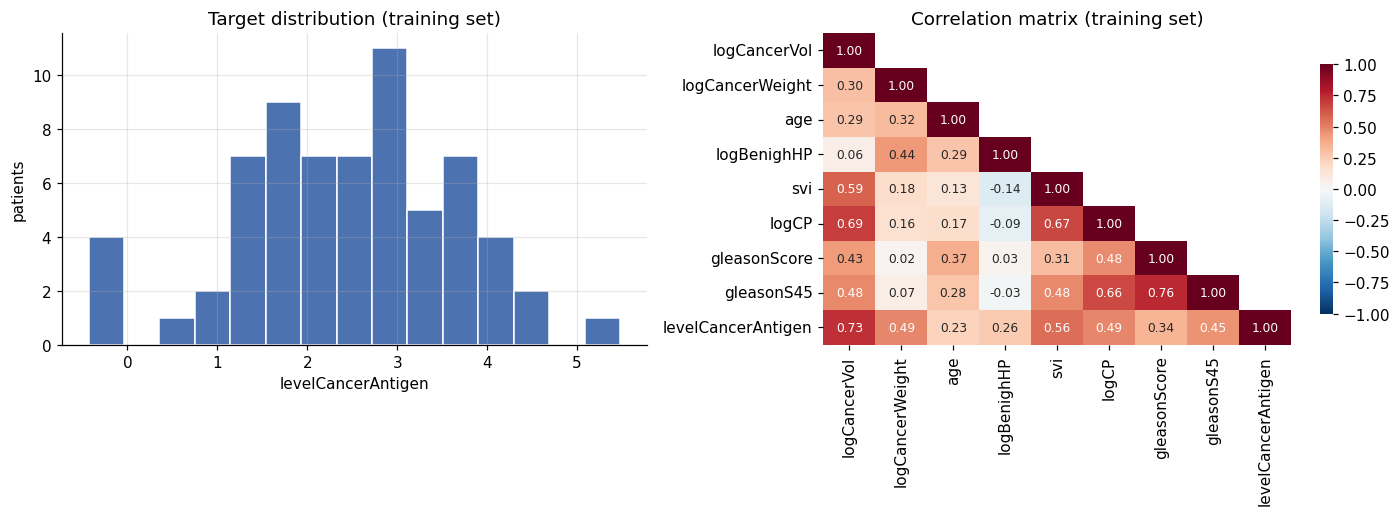

In [5]:
# Quick look at the distributions and the discrete / floor-valued variables
print("svi counts:", train_df["svi"].value_counts().to_dict())
print("gleasonScore counts:", train_df["gleasonScore"].value_counts().sort_index().to_dict())
print(f"logCP at its minimum ({train_df['logCP'].min():.3f}): {(train_df['logCP'] == train_df['logCP'].min()).mean():.0%} of training patients")
print(f"gleasonS45 == 0: {(train_df['gleasonS45'] == 0).mean():.0%} of training patients")
print(f"logBenighHP at its minimum: {(train_df['logBenighHP'] == train_df['logBenighHP'].min()).mean():.0%} of training patients")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(y_train, bins=15, edgecolor="white", color="#4C72B0")
axes[0].set(title="Target distribution (training set)", xlabel=TARGET, ylabel="patients")

corr = train_df[FEATURES + [TARGET]].corr()
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, bool), k=1), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, ax=axes[1], cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
axes[1].set(title="Correlation matrix (training set)")
axes[1].grid(False)
plt.tight_layout(); plt.show()

In [6]:
# Multicollinearity check: variance inflation factor, VIF_j = 1 / (1 - R^2_j),
# where R^2_j comes from regressing feature j on all the other features (training data only).
Z = (X_train - X_train.mean(0)) / X_train.std(0)
vif = []
for j in range(Z.shape[1]):
    A = np.column_stack([np.ones(len(Z)), np.delete(Z, j, axis=1)])
    beta = np.linalg.lstsq(A, Z[:, j], rcond=None)[0]
    r2 = 1 - (Z[:, j] - A @ beta).var() / Z[:, j].var()
    vif.append(1 / (1 - r2))
pd.Series(vif, index=FEATURES, name="VIF").round(2).to_frame()

,VIF
logCancerVol,2.32
logCancerWeight,1.47
age,1.36
logBenighHP,1.38
svi,2.05
logCP,3.12
gleasonScore,2.64
gleasonS45,3.31


---
## 3. Model training and model selection (14 marks)

### 3.1 Own implementation of cross-validation

`kfold_indices` shuffles the training patients and cuts them into *k* folds; `cv_fold_errors` fits a model on *k–1* folds (standardising with those folds only) and measures the mean squared error (MSE) on the held-out fold. `tune_penalty` repeats this over a grid of penalty values, with several different random fold assignments (*repeated* k-fold CV) so the result does not hinge on one lucky or unlucky split – important with only 67 patients.

Least squares has no complexity parameter, so it is simply fitted. I implement it directly with `numpy.linalg.lstsq`.

In [7]:
class OLS:
    # Ordinary least squares with an intercept, solved by least squares (no penalty).
    def fit(self, X, y):
        A = np.column_stack([np.ones(len(X)), X])
        beta = np.linalg.lstsq(A, y, rcond=None)[0]
        self.intercept_, self.coef_ = beta[0], beta[1:]
        return self
    def predict(self, X):
        return self.intercept_ + X @ self.coef_


def fit_predict(make_model, X_fit, y_fit, X_new):
    # Standardise using ONLY the fitting data (no leakage), fit, and predict for X_new.
    mu, sd = X_fit.mean(axis=0), X_fit.std(axis=0)
    model = make_model().fit((X_fit - mu) / sd, y_fit)
    return model.predict((X_new - mu) / sd), model


def kfold_indices(n, k, rng):
    # Own k-fold splitter: random permutation cut into k (nearly) equal folds -> list of (train_idx, val_idx).
    perm = rng.permutation(n)
    folds = np.array_split(perm, k)
    return [(np.setdiff1d(perm, f, assume_unique=True), f) for f in folds]


def cv_fold_errors(make_model, X, y, folds):
    # MSE on each held-out fold.
    errs = []
    for tr, va in folds:
        pred, _ = fit_predict(make_model, X[tr], y[tr], X[va])
        errs.append(np.mean((y[va] - pred) ** 2))
    return np.array(errs)


def tune_penalty(model_cls, grid, X, y, k=10, repeats=10, seed=SEED):
    # Repeated k-fold CV over a grid of penalty values (alpha).
    # Returns the mean CV-MSE curve, its approximate standard error, the best alpha and the 1-SE-rule alpha.
    rng = np.random.default_rng(seed)
    fold_sets = [kfold_indices(len(y), k, rng) for _ in range(repeats)]
    errs = np.zeros((repeats, len(grid), k))
    for r, folds in enumerate(fold_sets):
        for g, a in enumerate(grid):
            errs[r, g] = cv_fold_errors(lambda: model_cls(alpha=a), X, y, folds)
    cv_mean = errs.mean(axis=(0, 2))
    cv_se = (errs.std(axis=2, ddof=1) / np.sqrt(k)).mean(axis=0)     # SE of a single k-fold run, averaged over repeats
    best = int(np.argmin(cv_mean))
    within = np.where(cv_mean <= cv_mean[best] + cv_se[best])[0]     # 1-SE rule: simplest model within 1 SE of the best
    one_se = int(within.max())                                       # grid is increasing -> largest alpha = most regularised
    return dict(grid=np.asarray(grid), cv_mean=cv_mean, cv_se=cv_se, best_idx=best, best_alpha=grid[best],
                one_se_idx=one_se, one_se_alpha=grid[one_se])


# Penalty grids. Lasso: from alpha_max (all coefficients exactly zero) down four orders of magnitude.
Zs = (X_train - X_train.mean(0)) / X_train.std(0)
alpha_max = np.max(np.abs(Zs.T @ (y_train - y_train.mean()))) / len(y_train)
RIDGE_GRID = np.logspace(-3, 3, 40)
LASSO_GRID = np.logspace(np.log10(alpha_max) - 4, np.log10(alpha_max), 40)

make_ols   = lambda: OLS()
make_ridge = lambda a: (lambda: Ridge(alpha=a))
make_lasso = lambda a: (lambda: Lasso(alpha=a, max_iter=100_000))
print(f"Ridge grid: {RIDGE_GRID[0]:.3g} … {RIDGE_GRID[-1]:.3g} | Lasso grid: {LASSO_GRID[0]:.3g} … {LASSO_GRID[-1]:.3g} (40 values each, log-spaced)")

Ridge grid: 0.001 … 1e+03 | Lasso grid: 8.79e-05 … 0.879 (40 values each, log-spaced)


### 3.2 Least squares

OLS has no tuning parameter. Its 10-fold CV error (averaged over 10 repeats) is the baseline for the two penalised models.

In [8]:
rng = np.random.default_rng(SEED)
ols_folds = [kfold_indices(len(y_train), 10, rng) for _ in range(10)]
ols_errs = np.array([cv_fold_errors(make_ols, X_train, y_train, f) for f in ols_folds])   # (repeats, folds)
print(f"OLS   10-fold CV MSE (10 repeats): {ols_errs.mean():.4f}   (RMSE {np.sqrt(ols_errs.mean()):.4f})")

OLS   10-fold CV MSE (10 repeats): 0.5791   (RMSE 0.7610)


### 3.3 Ridge regression – choosing λ (called `alpha` in scikit-learn) by cross-validation

Ridge minimises `RSS + λ·Σβⱼ²`. A larger λ shrinks the coefficients toward zero: this adds *bias* but lowers *variance*, which helps when predictors are correlated and the sample is small. In the CV-MSE curve below, small λ gives (almost) the OLS fit, a modest amount of shrinkage lowers the error slightly, and too much shrinkage under-fits (high bias) so the error climbs steeply.

In [9]:
ridge_res = tune_penalty(Ridge, RIDGE_GRID, X_train, y_train)
print(f"Ridge: best alpha = {ridge_res['best_alpha']:.4g}  (CV-MSE {ridge_res['cv_mean'][ridge_res['best_idx']]:.4f} ± {ridge_res['cv_se'][ridge_res['best_idx']]:.4f})")
print(f"Ridge: 1-SE-rule alpha = {ridge_res['one_se_alpha']:.4g}")

Ridge: best alpha = 3.455  (CV-MSE 0.5688 ± 0.0899)
Ridge: 1-SE-rule alpha = 41.25


### 3.4 Lasso regression – choosing λ by cross-validation

Lasso minimises `RSS/(2n) + λ·Σ|βⱼ|`. The ℓ¹ penalty shrinks *and* sets some coefficients exactly to zero, so it performs variable selection – useful for the inference objective.

In [10]:
lasso_res = tune_penalty(Lasso, LASSO_GRID, X_train, y_train)
print(f"Lasso: best alpha = {lasso_res['best_alpha']:.4g}  (CV-MSE {lasso_res['cv_mean'][lasso_res['best_idx']]:.4f} ± {lasso_res['cv_se'][lasso_res['best_idx']]:.4f})")
print(f"Lasso: 1-SE-rule alpha = {lasso_res['one_se_alpha']:.4g}")

Lasso: best alpha = 0.01252  (CV-MSE 0.5709 ± 0.0909)
Lasso: 1-SE-rule alpha = 0.1683


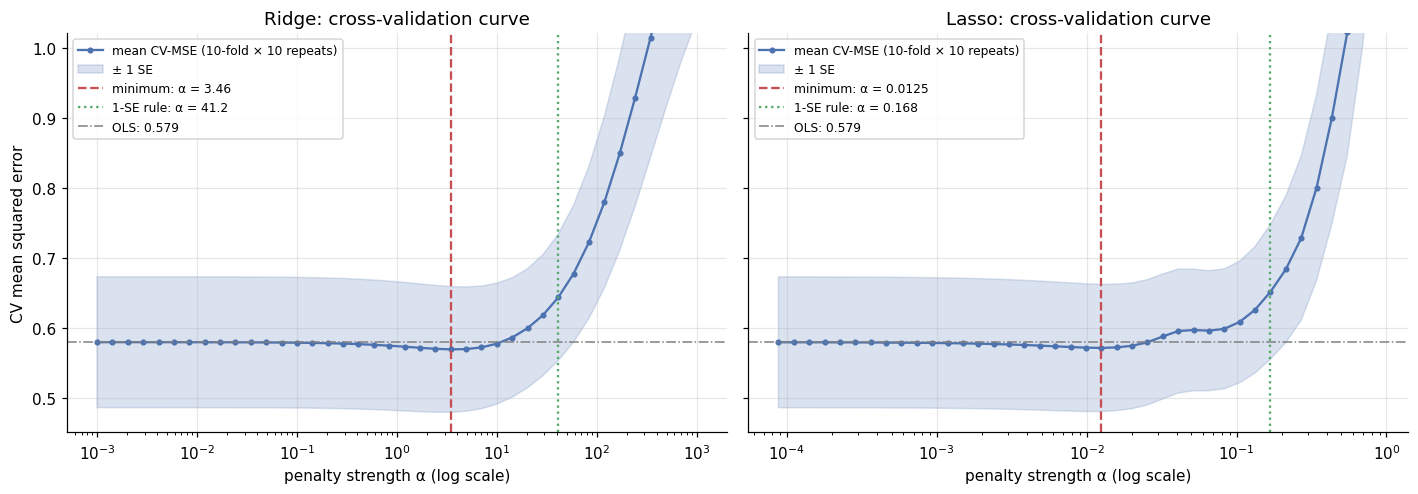

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, res, name in zip(axes, [ridge_res, lasso_res], ["Ridge", "Lasso"]):
    g, m, s = res["grid"], res["cv_mean"], res["cv_se"]
    ax.plot(g, m, "o-", ms=3, color="#4C72B0", label="mean CV-MSE (10-fold × 10 repeats)")
    ax.fill_between(g, m - s, m + s, alpha=0.2, color="#4C72B0", label="± 1 SE")
    ax.axvline(res["best_alpha"], color="#C44E52", ls="--", label=f"minimum: α = {res['best_alpha']:.3g}")
    ax.axvline(res["one_se_alpha"], color="#55A868", ls=":", label=f"1-SE rule: α = {res['one_se_alpha']:.3g}")
    ax.axhline(ols_errs.mean(), color="grey", ls="-.", lw=1, label=f"OLS: {ols_errs.mean():.3f}")
    ax.set(xscale="log", xlabel="penalty strength α (log scale)", title=f"{name}: cross-validation curve",
           ylim=((m - s).min() - 0.03, m.min() + 0.45))      # zoom in: the steep rise at large α would hide the minimum
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("CV mean squared error")
plt.tight_layout(); plt.show()

### 3.5 Choosing the best of the three models

Comparing the three models by the CV error that was *used to pick λ* would favour Ridge and Lasso slightly, because their λ was tuned on exactly those folds (an optimistically biased score). To compare fairly I use **nested cross-validation**: in each outer fold the penalty is re-chosen by an inner 10-fold CV using only the outer-training patients, and the resulting model is scored on the untouched outer-validation fold. OLS goes through exactly the same outer folds. The model with the lowest nested-CV error is selected. The test set is **not** used for this decision.

In [12]:
def nested_cv(kind, outer_sets, X, y, inner_k=10, seed=SEED):
    # Nested CV. kind in {"ols", "ridge", "lasso"}. Returns MSE per outer fold, shape (repeats, outer_k).
    out = np.zeros((len(outer_sets), len(outer_sets[0])))
    for r, folds in enumerate(outer_sets):
        for f, (tr, va) in enumerate(folds):
            if kind == "ols":
                make = make_ols
            else:
                cls, grid = (Ridge, RIDGE_GRID) if kind == "ridge" else (Lasso, LASSO_GRID)
                inner = tune_penalty(cls, grid, X[tr], y[tr], k=inner_k, repeats=1, seed=seed + 1000 * r + f)
                make = make_ridge(inner["best_alpha"]) if kind == "ridge" else make_lasso(inner["best_alpha"])
            pred, _ = fit_predict(make, X[tr], y[tr], X[va])
            out[r, f] = np.mean((y[va] - pred) ** 2)
    return out

rng = np.random.default_rng(SEED + 7)
outer_sets = [kfold_indices(len(y_train), 10, rng) for _ in range(5)]      # 5 repeats of outer 10-fold CV

nested = {k: nested_cv(k, outer_sets, X_train, y_train) for k in ["ols", "ridge", "lasso"]}

rows = []
for name, e in nested.items():
    d = e - nested["ols"]                                        # paired difference to OLS (same outer folds)
    rows.append({"model": name.upper() if name == "ols" else name.capitalize(),
                 "nested-CV MSE": e.mean(),
                 "SE": (e.std(axis=1, ddof=1) / np.sqrt(e.shape[1])).mean(),
                 "nested-CV RMSE": np.sqrt(e.mean()),
                 "MSE − OLS MSE": d.mean(),
                 "SE of difference": (d.std(axis=1, ddof=1) / np.sqrt(d.shape[1])).mean()})
cv_table = pd.DataFrame(rows).set_index("model")
print("Nested CV (5 repeats × 10 outer folds; penalty re-tuned inside every outer fold):")
cv_table.round(4)

Nested CV (5 repeats × 10 outer folds; penalty re-tuned inside every outer fold):


,nested-CV MSE,SE,nested-CV RMSE,MSE − OLS MSE,SE of difference
model,,,,,
OLS,0.6014,0.0974,0.7755,0.0000,0.0000
Ridge,0.6008,0.0943,0.7751,-0.0005,0.0170
Lasso,0.6078,0.0973,0.7796,0.0064,0.0167


In [13]:
# Fit each model on the FULL training set (standardised with training statistics) using the CV-chosen penalty.
final_models = {
    "OLS":   make_ols,
    "Ridge": make_ridge(ridge_res["best_alpha"]),
    "Lasso": make_lasso(lasso_res["best_alpha"]),
}

def regression_metrics(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": np.mean(np.abs(y_true - y_pred)),
            "R²": 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)}

test_rows, fitted, test_pred = [], {}, {}
for name, make in final_models.items():
    pred, model = fit_predict(make, X_train, y_train, X_test)
    fitted[name], test_pred[name] = model, pred
    tr_pred, _ = fit_predict(make, X_train, y_train, X_train)
    m = regression_metrics(y_test, pred)
    test_rows.append({"model": name, "train MSE": np.mean((y_train - tr_pred) ** 2),
                      "nested-CV MSE": cv_table.loc[name.upper() if name == "OLS" else name, "nested-CV MSE"],
                      "test MSE": m["MSE"], "test RMSE": m["RMSE"], "test MAE": m["MAE"], "test R²": m["R²"]})

baseline_mse = np.mean((y_test - y_train.mean()) ** 2)
results = pd.DataFrame(test_rows).set_index("model")
print(f"Reference: predicting the training mean for every test patient gives test MSE = {baseline_mse:.4f}\n")
best_name = results["nested-CV MSE"].idxmin()
print(f"Model selected by nested cross-validation: {best_name}")
results.round(4)

Reference: predicting the training mean for every test patient gives test MSE = 1.0567

Model selected by nested cross-validation: Ridge


,train MSE,nested-CV MSE,test MSE,test RMSE,test MAE,test R²
model,,,,,,
OLS,0.4392,0.6014,0.5213,0.7220,0.5234,0.5034
Ridge,0.4438,0.6008,0.4990,0.7064,0.5170,0.5246
Lasso,0.4424,0.6078,0.4946,0.7033,0.5105,0.5288


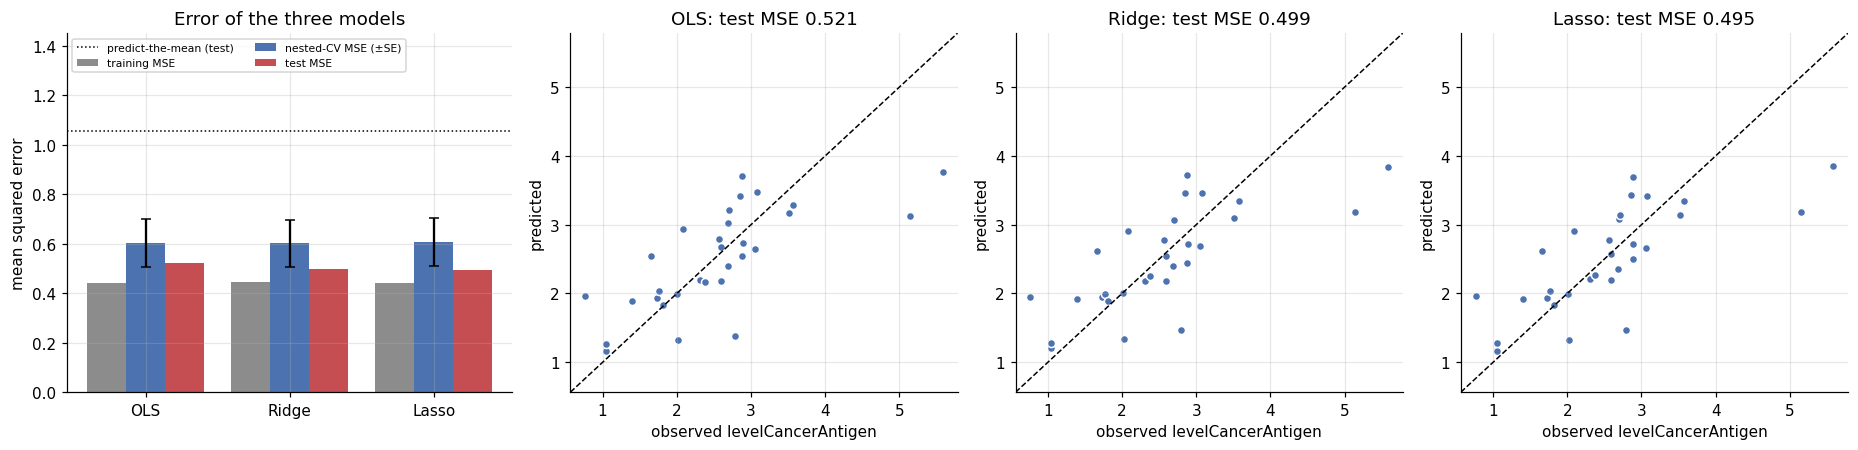

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1.15, 1, 1, 1]})

# (a) error comparison
ax = axes[0]
names = list(results.index)
x = np.arange(len(names)); w = 0.27
se = cv_table["SE"].to_numpy()
ax.bar(x - w, results["train MSE"], w, label="training MSE", color="#8C8C8C")
ax.bar(x,      results["nested-CV MSE"], w, yerr=se, capsize=3, label="nested-CV MSE (±SE)", color="#4C72B0")
ax.bar(x + w,  results["test MSE"], w, label="test MSE", color="#C44E52")
ax.axhline(baseline_mse, color="k", ls=":", lw=1, label="predict-the-mean (test)")
ax.set(xticks=x, xticklabels=names, ylabel="mean squared error", title="Error of the three models")
ax.set_ylim(0, 1.45); ax.legend(fontsize=7, loc="upper left", ncol=2)

# (b–d) predicted vs observed on the test set
lims = [min(y_test.min(), *[p.min() for p in test_pred.values()]) - 0.2,
        max(y_test.max(), *[p.max() for p in test_pred.values()]) + 0.2]
for ax, name in zip(axes[1:], names):
    ax.scatter(y_test, test_pred[name], s=28, color="#4C72B0", edgecolor="white")
    ax.plot(lims, lims, "k--", lw=1)
    ax.set(xlim=lims, ylim=lims, xlabel="observed levelCancerAntigen", ylabel="predicted",
           title=f"{name}: test MSE {results.loc[name, 'test MSE']:.3f}")
plt.tight_layout(); plt.show()

### 3.6 Interpretation: which model is best for prediction? (explained with ML principles)

*(Numbers below are from the run shown above, `SEED = 42`.)*

**Result.** In nested cross-validation the three models are essentially tied: OLS 0.601, Ridge 0.601, Lasso 0.608 (MSE; RMSE ≈ 0.78). The paired differences to OLS (−0.0005 for Ridge, +0.006 for Lasso) are tiny compared with their standard errors (≈ 0.017). **Ridge has the lowest nested-CV error and is therefore selected, but this is a tie-break rather than evidence that it is truly better.** On the 30 held-out patients the test MSEs are OLS 0.521, Ridge 0.499 and Lasso 0.495. That ordering is *not* used for selection, and with 30 patients a gap of 0.02–0.03 is within noise (a single patient can move the MSE by that much). What the test set does show clearly is that all three models roughly halve the error of simply predicting the training mean (test MSE 1.057) and explain about half of the variance (R² ≈ 0.50–0.53).

**Why do penalised models not clearly beat OLS here?**

* **Bias–variance trade-off.** Ridge/Lasso trade a little bias for lower variance. The gain depends on how much variance OLS has. With 67 patients, only 8 predictors and moderate collinearity (largest VIF 3.3, nothing near the usual warning level of 5–10), OLS's variance is already small, so there is little to be gained: the CV curves in 3.3–3.4 are flat for small λ (where the penalised fit equals OLS) and the minimum is shallow. Beyond the optimum, extra shrinkage adds bias and the error rises steeply (under-fitting).
* **Training vs. generalisation error.** Training MSE (≈ 0.44) is clearly below the CV/test error (≈ 0.50–0.60) for every model: training error is an optimistic estimate, which is why model selection must use held-out data.
* **Ridge vs. Lasso.** Almost all predictors carry some signal and several are correlated, a situation in which ridge's smooth ℓ² shrinkage tends to do at least as well as Lasso's ℓ¹ selection (Lasso has to pick one of a group of correlated predictors, which adds variance). This matches the marginally worse nested-CV error of Lasso.
* **Limits of a linear model.** All three models under-predict the two test patients with the highest antigen levels (observed ≈ 5.2 and 5.6, predicted ≈ 3.2 and 3.8, off by about 2 units), which points to non-linearity or heavy tails that a linear model cannot capture.
* **1-SE rule.** The more heavily regularised "1-SE" penalties (marked in the CV plots) have CV error within one standard error of the minimum and give simpler models; I report the minimum-error penalty as the main result and mention the 1-SE choice as a more conservative alternative.

---
## 4. Inference – which clinical measures influence the cancer antigen level? (5 marks)

The selected model is used to rank the predictors. Because every feature was standardised, a coefficient is the change in `levelCancerAntigen` for a **one-standard-deviation increase** in that feature, holding the others fixed – so coefficient sizes are directly comparable. I support the ranking with three complementary views:

1. the fitted coefficients of the three models side by side;
2. **regularisation paths** – how the coefficients shrink as the penalty grows (predictors that survive strong shrinkage are the most important);
3. **bootstrap confidence intervals** (1000 resamples of the training patients, penalty held at the CV-chosen value) – penalised models give no p-values, so the bootstrap shows how stable each coefficient is. As a reference, the classical OLS t-tests are also shown.

In [15]:
mu, sd = X_train.mean(0), X_train.std(0)
coef_table = pd.DataFrame({name: fitted[name].coef_ for name in fitted}, index=FEATURES)
coef_table["|best model|"] = coef_table[best_name].abs()
coef_table = coef_table.sort_values("|best model|", ascending=False)
print(f"Standardised coefficients (effect of +1 SD in the feature). Rows sorted by |{best_name} coefficient|:")
coef_table.drop(columns="|best model|").round(3)

Standardised coefficients (effect of +1 SD in the feature). Rows sorted by |Ridge coefficient|:


,OLS,Ridge,Lasso
logCancerVol,0.711,0.633,0.673
svi,0.307,0.289,0.281
logCancerWeight,0.290,0.287,0.283
gleasonS45,0.275,0.221,0.218
logBenighHP,0.210,0.203,0.197
logCP,-0.287,-0.192,-0.207
age,-0.141,-0.119,-0.114
gleasonScore,-0.021,0.005,-0.000


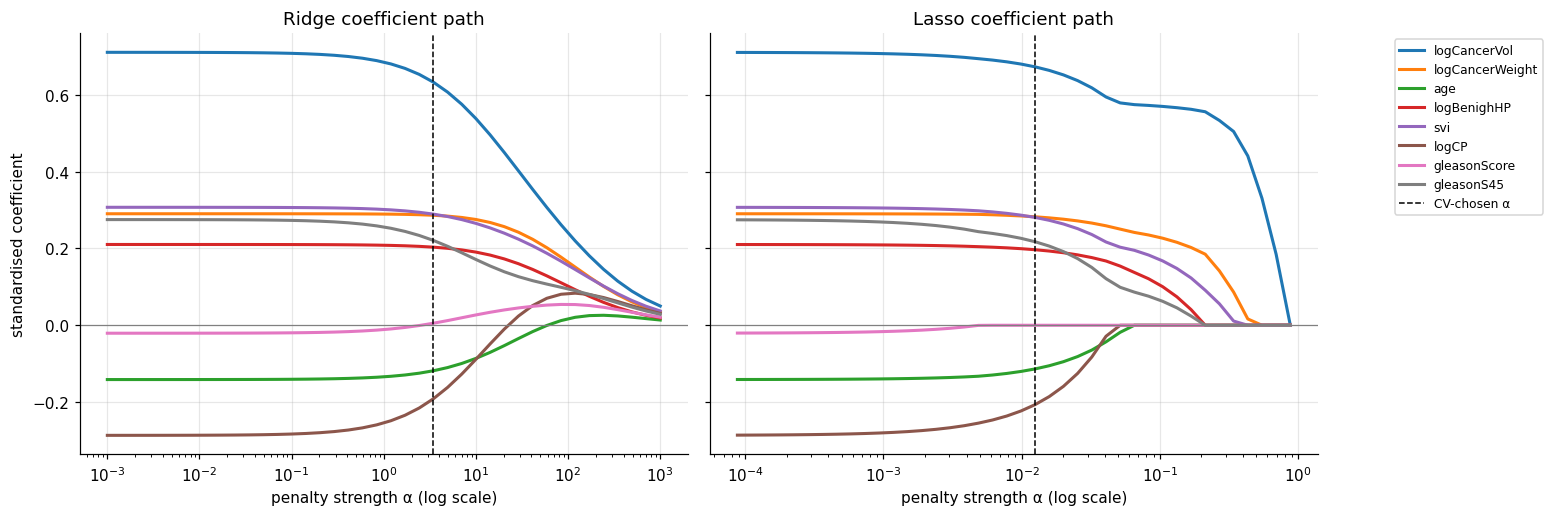

In [16]:
# Regularisation paths: coefficients of Ridge and Lasso (fitted on the full training set) over the penalty grid.
def path(cls, grid):
    return np.array([cls(alpha=a, **({"max_iter": 100_000} if cls is Lasso else {})).fit(Zs, y_train).coef_ for a in grid])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
palette = sns.color_palette("tab10", len(FEATURES))
for ax, (cls, grid, res, name) in zip(axes, [(Ridge, RIDGE_GRID, ridge_res, "Ridge"), (Lasso, LASSO_GRID, lasso_res, "Lasso")]):
    P = path(cls, grid)
    for j, f in enumerate(FEATURES):
        ax.plot(grid, P[:, j], label=f, color=palette[j], lw=2)
    ax.axvline(res["best_alpha"], color="k", ls="--", lw=1, label="CV-chosen α")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xscale="log", xlabel="penalty strength α (log scale)", title=f"{name} coefficient path")
axes[0].set_ylabel("standardised coefficient")
axes[1].legend(fontsize=8, loc="upper right", bbox_to_anchor=(1.38, 1.0))
plt.tight_layout(); plt.show()

In [17]:
# Bootstrap (own implementation): resample the training patients with replacement, refit the selected model
# with the penalty fixed at its CV-chosen value (standardising inside each resample), and record the coefficients.
B = 1000
rng = np.random.default_rng(SEED + 99)
make_best = final_models[best_name]
boot = np.zeros((B, len(FEATURES)))
for b in range(B):
    idx = rng.integers(0, len(y_train), len(y_train))
    m_b, s_b = X_train[idx].mean(0), X_train[idx].std(0)
    s_b[s_b == 0] = 1.0                                         # guard against a constant column in a resample
    boot[b] = make_best().fit((X_train[idx] - m_b) / s_b, y_train[idx]).coef_

ci = pd.DataFrame({
    "coef": fitted[best_name].coef_,
    "boot 2.5%": np.percentile(boot, 2.5, axis=0),
    "boot 97.5%": np.percentile(boot, 97.5, axis=0),
    "% resamples with same sign": (np.sign(boot) == np.sign(fitted[best_name].coef_)).mean(axis=0) * 100,
}, index=FEATURES)
ci["95% CI excludes 0"] = (ci["boot 2.5%"] > 0) | (ci["boot 97.5%"] < 0)
ci = ci.reindex(coef_table.index)
print(f"{best_name}: bootstrap 95% percentile intervals for the standardised coefficients ({B} resamples)")
ci.round(3)

Ridge: bootstrap 95% percentile intervals for the standardised coefficients (1000 resamples)


,coef,boot 2.5%,boot 97.5%,% resamples with same sign,95% CI excludes 0
logCancerVol,0.633,0.374,0.850,100.0,True
svi,0.289,0.047,0.516,99.0,True
logCancerWeight,0.287,0.072,0.469,99.7,True
gleasonS45,0.221,0.036,0.444,99.1,True
logBenighHP,0.203,0.001,0.422,97.5,True
logCP,-0.192,-0.391,0.026,95.9,False
age,-0.119,-0.255,0.082,90.5,False
gleasonScore,0.005,-0.241,0.203,55.0,False


In [18]:
# Reference: classical OLS inference (t-tests) on the standardised training data, computed from first principles.
A = np.column_stack([np.ones(len(Zs)), Zs])
beta = np.linalg.lstsq(A, y_train, rcond=None)[0]
dof = len(y_train) - A.shape[1]
sigma2 = np.sum((y_train - A @ beta) ** 2) / dof
se_beta = np.sqrt(np.diag(sigma2 * np.linalg.inv(A.T @ A)))
t_stat = beta / se_beta
p_val = 2 * stats.t.sf(np.abs(t_stat), dof)
tcrit = stats.t.ppf(0.975, dof)
ols_inf = pd.DataFrame({"coef": beta, "std. error": se_beta, "t": t_stat, "p-value": p_val,
                        "95% CI low": beta - tcrit * se_beta, "95% CI high": beta + tcrit * se_beta},
                       index=["(intercept)"] + FEATURES)
ols_inf = pd.concat([ols_inf.iloc[:1], ols_inf.iloc[1:].reindex(coef_table.index)])
print(f"OLS t-tests on standardised features (residual degrees of freedom = {dof})")
ols_inf.round(3)

OLS t-tests on standardised features (residual degrees of freedom = 58)


,coef,std. error,t,p-value,95% CI low,95% CI high
(intercept),2.452,0.087,28.182,0.000,2.278,2.627
logCancerVol,0.711,0.133,5.366,0.000,0.446,0.976
svi,0.307,0.124,2.469,0.017,0.058,0.556
logCancerWeight,0.290,0.106,2.751,0.008,0.079,0.502
gleasonS45,0.275,0.158,1.738,0.088,-0.042,0.592
logBenighHP,0.210,0.102,2.056,0.044,0.006,0.415
logCP,-0.287,0.154,-1.867,0.067,-0.594,0.021
age,-0.141,0.101,-1.396,0.168,-0.344,0.061
gleasonScore,-0.021,0.142,-0.147,0.884,-0.304,0.263


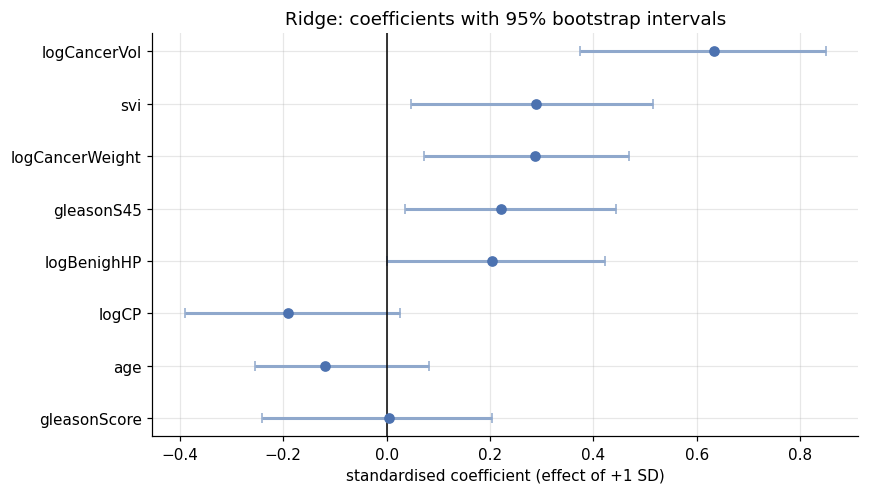

In [19]:
# Final ranking figure: coefficients with bootstrap intervals for the selected model.
order = ci.index[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
y_pos = np.arange(len(order))
ax.errorbar(ci.loc[order, "coef"], y_pos,
            xerr=[ci.loc[order, "coef"] - ci.loc[order, "boot 2.5%"], ci.loc[order, "boot 97.5%"] - ci.loc[order, "coef"]],
            fmt="o", color="#4C72B0", ecolor="#8FA8CC", capsize=3, lw=2)
ax.axvline(0, color="k", lw=1)
ax.set(yticks=y_pos, yticklabels=order, xlabel="standardised coefficient (effect of +1 SD)",
       title=f"{best_name}: coefficients with 95% bootstrap intervals")
plt.tight_layout(); plt.show()

### 4.1 Interpretation: which clinical measures influence the cancer antigen level?

**Conclusion (selected model: Ridge; standardised coefficients, 95 % bootstrap intervals).**

1. **`logCancerVol` is by far the most influential measure.** One standard deviation more log cancer volume is associated with about +0.63 higher `levelCancerAntigen` (95 % interval 0.37 – 0.85), more than twice the size of any other coefficient. It also has the largest coefficient at every penalty value in both regularisation paths, is the last coefficient Lasso shrinks to zero, and has the strongest OLS t-statistic (t = 5.4, p < 0.001). The evidence is consistent across every method used.
2. **Four further measures have modest positive associations:** `svi` (+0.29), `logCancerWeight` (+0.29), `gleasonS45` (+0.22) and `logBenighHP` (+0.20). Their bootstrap intervals exclude zero, but the lower limits are close to zero (0.00 – 0.07), so these effects are much less certain than that of `logCancerVol`. `logBenighHP` is borderline (lower limit 0.001, OLS p = 0.044) and `gleasonS45` is not significant in the OLS t-test (p = 0.088), so I regard them as *probably* positive rather than established. (A percentile bootstrap of a shrunken estimator does not have exact coverage, so the intervals should be read as a stability check, not as formal tests.)
3. **`logCP`, `age` and `gleasonScore` cannot be distinguished from zero.** Their intervals include zero, and the sign of the `gleasonScore` coefficient (≈ 0.005) flips in 45 % of resamples. In the Lasso path these three are the first to be removed (`gleasonScore` immediately, `age` and `logCP` soon after).

**A caution about what "influential" means here.** Coefficients are *conditional* effects: the association of one measure with the antigen level *after accounting for the other measures*. This explains two things that look odd at first. `logCP` has a clearly positive raw correlation with the target (r ≈ 0.49) but a *negative* coefficient, because it is strongly correlated with `logCancerVol` (r ≈ 0.69) and `svi` (r ≈ 0.67), which already carry that information; its remaining unique contribution is small and uncertain. Likewise `gleasonScore` (raw r ≈ 0.34) is redundant given `gleasonS45` (r ≈ 0.76 between them). A small coefficient therefore means "adds little *beyond the others*", not "unrelated to the antigen". Negative coefficients on correlated predictors should not be read as protective effects.

**Limitations.** The sample is small (67 training patients), the data are observational, so these are **associations, not causal effects**; the model is linear and additive; and the penalty was tuned on the same patients as the intervals, so intervals are somewhat optimistic. The ranking is best viewed as hypotheses for clinical follow-up, with `logCancerVol` the one finding that is both large and stable.

### Summary of Task 1

| Objective | Outcome |
|---|---|
| Prediction | OLS, Ridge and Lasso perform equivalently (nested-CV MSE ≈ 0.60, test MSE ≈ 0.50 – 0.52 vs. 1.06 for the mean predictor). **Ridge** is selected by nested CV (λ = 3.46 on the standardised features). |
| Inference | `logCancerVol` dominates; `svi`, `logCancerWeight`, `gleasonS45` and `logBenighHP` contribute modestly; `logCP`, `age` and `gleasonScore` add no reliable information once the others are known. |